# Лабораторная №1. Scan-matching. Шаврин А.П. Виноградова М.О.

## Imports

In [50]:
from __future__ import annotations
from dataclasses import dataclass
from functools import cached_property
import math
import time
import numpy as np
import matplotlib.pyplot as plt
from skimage.draw import line as skimage_line
from scipy.ndimage import distance_transform_edt, maximum_filter

## Core

In [51]:
@dataclass(frozen=True, slots=True)
class Point:
    x: float
    y: float


@dataclass(frozen=True, slots=True)
class Vector:
    x: float
    y: float


@dataclass(frozen=True, slots=True)
class Segment:
    a: Point
    b: Point


@dataclass(frozen=True, slots=True)
class Ray:
    origin: Point
    direction: Vector

    @classmethod
    def from_angle(cls, origin: Point, angle: float) -> Ray:
        return cls(origin, Vector(math.cos(angle), math.sin(angle)))


@dataclass(frozen=True, slots=True)
class Pose:
    position: Point
    theta: float

    def compose(self, other: Pose) -> Pose:
        c, s = math.cos(self.theta), math.sin(self.theta)
        return Pose(
            position=Point(
                x = c * other.position.x - s * other.position.y + self.position.x,
                y = s * other.position.x + c * other.position.y + self.position.y
            ),
            theta = self.theta + other.theta,
        )

    def inverse(self) -> Pose:
        c, s = math.cos(self.theta), math.sin(self.theta)
        return Pose(
            position=Point(
                x = -c * self.position.x - s * self.position.y,
                y = s * self.position.x - c * self.position.y
            ),
            theta = -self.theta,
        )

    def apply(self, points: np.ndarray) -> np.ndarray:
        c, s = math.cos(self.theta), math.sin(self.theta)
        R = np.array([[c, -s], [s, c]])
        return points @ R.T + np.array([self.position.x, self.position.y])


@dataclass(frozen=True, slots=True)
class Scan:
    angles: np.ndarray
    ranges: np.ndarray

    def __post_init__(self):
        if len(self.angles) != len(self.ranges):
            raise ValueError(f"angles ({len(self.angles)}) != ranges ({len(self.ranges)})")
        self.angles.flags.writeable = False
        self.ranges.flags.writeable = False


@dataclass
class Room:
    polygon: list[Point]    # вершины против часовой

    @property
    def n_vertices(self) -> int:
        return len(self.polygon)

    @cached_property
    def segments(self) -> list[Segment]:
        n = self.n_vertices
        return [Segment(self.polygon[i], self.polygon[(i+1)%n]) for i in range(n)]


@dataclass(frozen=True)
class GridSpec:
    origin: Point
    resolution: float
    shape: tuple[int, int]

    @property
    def height(self) -> int:
        return self.shape[0]

    @property
    def width(self) -> int:
        return self.shape[1]

    @classmethod
    def covering(cls, points: np.ndarray, margin: float = 1.0, resolution: float = 0.05) -> GridSpec:
        x0, y0 = points.min(axis=0) - margin
        x1, y1 = points.max(axis=0) + margin
        W = int(np.ceil((x1 - x0) / resolution))
        H = int(np.ceil((y1 - y0) / resolution))
        return cls(Point(float(x0), float(y0)), resolution, (H, W))

    def expanded(self, margin: float) -> GridSpec:
        margin_cells = int(np.ceil(margin / self.resolution))
        if margin_cells <= 0:
            return self
        distance = margin_cells * self.resolution
        return GridSpec(
            Point(self.origin.x - distance, self.origin.y - distance),
            self.resolution,
            (self.height + 2 * margin_cells, self.width + 2 * margin_cells),
        )

    def to_cell(self, points: np.ndarray) -> tuple[np.ndarray, np.ndarray]:
        fx = (points[:, 0] - self.origin.x) / self.resolution
        fy = (points[:, 1] - self.origin.y) / self.resolution
        return np.floor(fx).astype(int), np.floor(fy).astype(int)

    def contains(self, cell_x: np.ndarray, cell_y: np.ndarray) -> np.ndarray:
        return (cell_x >= 0) & (cell_x < self.width) & (cell_y >= 0) & (cell_y < self.height)

    @property
    def extent(self) -> tuple[float, float, float, float]:
        x0, y0 = self.origin.x, self.origin.y
        return x0, x0 + self.width * self.resolution, y0, y0 + self.height * self.resolution


In [52]:
def polar_to_local(scan: Scan) -> np.ndarray:
    return np.column_stack([scan.ranges * np.cos(scan.angles), scan.ranges * np.sin(scan.angles)])

In [53]:
def bresenham(x0: int, y0: int, x1: int, y1: int) -> list[tuple[int, int]]:
    rr, cc = skimage_line(y0, x0, y1, x1)
    return list(zip(cc.tolist(), rr.tolist()))

## Pose generator

In [54]:
class PoseGenerator:
    def __init__(self, room: Room, rng, wall_margin: float = 0.5):
        self.room = room
        self.rng = rng
        self.wall_margin = wall_margin

    @staticmethod
    def _signed_dist_to_wall(point: Point, segment: Segment) -> float:
        ax, ay = segment.a.x, segment.a.y
        ex, ey = segment.b.x - ax, segment.b.y - ay
        cross = ex * (point.y - ay) - ey * (point.x - ax)
        return cross / math.hypot(ex, ey)

    def is_valid(self, pose: Pose):
        point = pose.position
        for segment in self.room.segments:
            if self._signed_dist_to_wall(point, segment) < self.wall_margin:
                return False
        return True

    def random(self, tries: int = 10_000) -> Pose:
        xs = [point.x for point in self.room.polygon]
        ys = [point.y for point in self.room.polygon]
        for _ in range(tries):
            x = self.rng.uniform(min(xs), max(xs))
            y = self.rng.uniform(min(ys), max(ys))
            theta = self.rng.uniform(-np.pi, np.pi)
            pose = Pose(Point(x, y), theta)
            if self.is_valid(pose):
                return pose
        raise RuntimeError("не удалось сгенерировать валидную позу")

## RayCaster

In [55]:
class RayCaster:
    _EPS = 1e-9
    _EPS_PARALLEL = 1e-9

    def intersect_segment(self, ray: Ray, segment: Segment) -> float | None:
        ox, oy = ray.origin.x, ray.origin.y
        dx, dy = ray.direction.x, ray.direction.y
        ax, ay = segment.a.x, segment.a.y
        ex, ey = segment.b.x - ax, segment.b.y - ay

        denom = dx * ey - dy * ex
        if abs(denom) < self._EPS_PARALLEL * math.hypot(ex, ey):
            return None

        t = ((ax - ox) * ey - (ay - oy) * ex) / denom
        u = ((ax - ox) * dy - (ay - oy) * dx) / denom
        if t > self._EPS and 0.0 <= u <= 1.0:
            return float(t)
        return None


    def cast(self, ray: Ray, room: Room) -> float | None:
        best = None
        for segment in room.segments:
            t = self.intersect_segment(ray, segment)
            if t is not None and (best is None or t < best):
                best = t
        return best

## Lidar

In [56]:
class Lidar:
    def __init__(self, ray_caster: RayCaster  | None = None, angle_step: float = math.pi / 360, max_range: float = 10.0, noise_std: float = 0.02):
        self.ray_caster = ray_caster if ray_caster is not None else RayCaster()
        self.angle_step = angle_step
        self.max_range = max_range
        self.noise_std = noise_std

    @property
    def num_rays(self) -> int:
        return int(round(2 * math.pi / self.angle_step))

    def scan(self, pose: Pose, room: Room, rng: np.random.Generator | None = None) -> Scan:
        n = self.num_rays
        angles = np.arange(n) * self.angle_step
        ranges = np.empty(n)

        for i, angle in enumerate(angles):
            ray = Ray.from_angle(pose.position, pose.theta + angle)
            t = self.ray_caster.cast(ray, room)
            ranges[i] = t if t is not None and t < self.max_range else math.nan

        if rng is not None:
            ranges = ranges + rng.normal(0, self.noise_std, len(ranges))

        mask = ~np.isnan(ranges)
        return Scan(angles=angles[mask], ranges=ranges[mask])

## Map

In [57]:
class OccupancyGrid:
    def __init__(
        self, 
        grid_spec: GridSpec, 
        prob_hit=0.7, 
        prob_miss=0.4, 
        log_odds_min=-2.0, 
        log_odds_max=3.5
    ):
        self.grid_spec = grid_spec
        self.log_odds = np.zeros(grid_spec.shape, np.float32)
        self.prob_hit = prob_hit
        self.prob_miss = prob_miss
        self.log_odds_hit  = math.log(prob_hit  / (1 - prob_hit))
        self.log_odds_miss = math.log(prob_miss / (1 - prob_miss))
        self.log_odds_min = log_odds_min
        self.log_odds_max = log_odds_max

    def integrate(self, scan: Scan, pose: Pose) -> OccupancyGrid:
        points = pose.apply(polar_to_local(scan))
        cell_x, cell_y = self.grid_spec.to_cell(points)
        in_bounds = self.grid_spec.contains(cell_x, cell_y)

        ox, oy = self.grid_spec.to_cell(np.array([[pose.position.x, pose.position.y]]))
        ox, oy = int(ox[0]), int(oy[0])
        for hit_x, hit_y in zip(cell_x[in_bounds], cell_y[in_bounds]):
            for px, py in bresenham(ox, oy, hit_x, hit_y)[:-1]:
                if 0 <= py < self.grid_spec.shape[0] and 0 <= px < self.grid_spec.shape[1]:
                    self.log_odds[py, px] += self.log_odds_miss

        np.add.at(self.log_odds, (cell_y[in_bounds], cell_x[in_bounds]), self.log_odds_hit)
        np.clip(self.log_odds, self.log_odds_min, self.log_odds_max, out=self.log_odds)
        return self

    def probabilities(self) -> np.ndarray:
        probabilities = (1.0 / (1.0 + np.exp(-self.log_odds))).astype(np.float32)
        return probabilities

    def occupied(self, threshold: float = 0.65) -> np.ndarray:
        return self.probabilities() > threshold

In [58]:
class Mapper:
    def __init__(self, resolution: float = 0.05, margin: float = 1.0):
        self.resolution, self.margin = resolution, margin

    def build(self, scan: Scan, pose: Pose = None) -> OccupancyGrid:
        pose = pose or Pose(Point(0.0, 0.0), 0.0)
        points = pose.apply(polar_to_local(scan))
        grid_spec = GridSpec.covering(points, self.margin, self.resolution)
        return OccupancyGrid(grid_spec).integrate(scan, pose)


## Correlative Scan Matching

In [59]:
class LikelihoodField:
    def __init__(self, occupancy_grid: OccupancyGrid, sigma: float = 0.15, occupied_threshold: float = 0.65, margin: float = 0.0):
        self.sigma = sigma
        self.grid_spec = occupancy_grid.grid_spec.expanded(margin)

        ys, xs = np.nonzero(occupancy_grid.occupied(occupied_threshold))
        world = np.column_stack([
            occupancy_grid.grid_spec.origin.x + (xs + 0.5) * occupancy_grid.grid_spec.resolution,
            occupancy_grid.grid_spec.origin.y + (ys + 0.5) * occupancy_grid.grid_spec.resolution,
        ])
        occupied = np.zeros(self.grid_spec.shape, bool)
        cell_x, cell_y = self.grid_spec.to_cell(world)
        in_bounds = self.grid_spec.contains(cell_x, cell_y)
        occupied[cell_y[in_bounds], cell_x[in_bounds]] = True

        distance = distance_transform_edt(~occupied) * self.grid_spec.resolution
        self.likelihood_field = np.exp(-0.5 * (distance / sigma) ** 2).astype(np.float32)
        self._hier = {}

    def score(self, points: np.ndarray, grid: np.ndarray | None = None) -> float:
        fx = (points[:, 0] - self.grid_spec.origin.x) / self.grid_spec.resolution - 0.5
        fy = (points[:, 1] - self.grid_spec.origin.y) / self.grid_spec.resolution - 0.5
        cell_x0 = np.floor(fx).astype(int)
        cell_y0 = np.floor(fy).astype(int)
        fraction_x = fx - cell_x0
        fraction_y = fy - cell_y0
        H, W = self.grid_spec.shape
        cell_x0_clipped = np.clip(cell_x0, 0, W - 1)
        cell_x1_clipped = np.clip(cell_x0 + 1, 0, W - 1)
        cell_y0_clipped = np.clip(cell_y0, 0, H - 1)
        cell_y1_clipped = np.clip(cell_y0 + 1, 0, H - 1)
        f = self.likelihood_field if grid is None else grid
        return float((
            ((f[cell_y0_clipped, cell_x0_clipped] * (1 - fraction_x) + f[cell_y0_clipped, cell_x1_clipped] * fraction_x) * (1 - fraction_y))
            + ((f[cell_y1_clipped, cell_x0_clipped] * (1 - fraction_x) + f[cell_y1_clipped, cell_x1_clipped] * fraction_x) * fraction_y)
        ).sum())

    def hierarchy(self, max_hierarchy_level: int):
        if max_hierarchy_level not in self._hier:
            grids = [self.likelihood_field]
            for hierarchy_level in range(1, max_hierarchy_level + 1):
                grids.append(maximum_filter(self.likelihood_field, size=2 ** hierarchy_level + 1, mode="constant"))
            self._hier[max_hierarchy_level] = grids
        return self._hier[max_hierarchy_level]


In [60]:
class ScanMatcher:
    def __init__(self, window_xy: float = 8.0, window_theta: float = math.pi):
        self.window_xy = window_xy
        self.window_theta = window_theta

    def required_margin(self, max_scan_radius: float, sigma: float, resolution: float) -> float:
        rotation_margin = 2.0 * max_scan_radius * math.sin(
            min(self.window_theta, math.pi) / 2.0
        )
        return self.window_xy + rotation_margin + 3.0 * sigma + 2.0 * resolution

    def match(self, likelihood_field: LikelihoodField, scan: Scan, prior_pose: Pose | None = None) -> Pose:
        prior_pose = prior_pose or Pose(Point(0.0, 0.0), 0.0)
        points = polar_to_local(scan)
        if len(points) == 0:
            return prior_pose

        r = likelihood_field.grid_spec.resolution
        max_scan_radius = float(np.linalg.norm(points, axis=1).max())
        theta_step = 2.0 * math.asin(r / (2.0 * max_scan_radius)) if max_scan_radius > r else math.pi / 18.0

        xy_step_count = int(self.window_xy / r)
        theta_step_count = int(self.window_theta / theta_step)

        max_hierarchy_level = max(1, math.ceil(math.log2(2 * xy_step_count + 1)))
        max_hierarchy_level = min(max_hierarchy_level, 6)
        precomputed_fields = likelihood_field.hierarchy(max_hierarchy_level)

        def pose_of(cell_x: int, cell_y: int, cell_theta: int, hierarchy_level: int) -> Pose:
            off = ((2 ** hierarchy_level) - 1) / 2.0
            return Pose(
                Point(
                    prior_pose.position.x + r * (cell_x + off),
                    prior_pose.position.y + r * (cell_y + off)
                ),
                prior_pose.theta + theta_step * (cell_theta + off),
            )

        def score(cell_x, cell_y, cell_theta, hierarchy_level, grid) -> float:
            return likelihood_field.score(pose_of(cell_x, cell_y, cell_theta, hierarchy_level).apply(points), grid)

        coarse_step = 2 ** max_hierarchy_level
        stack = [
            (cell_x, cell_y, cell_theta, max_hierarchy_level)
            for cell_x in range(-xy_step_count, xy_step_count + 1, coarse_step)
            for cell_y in range(-xy_step_count, xy_step_count + 1, coarse_step)
            for cell_theta in range(-theta_step_count, theta_step_count + 1, coarse_step)
        ]
        stack = [(score(*candidate, precomputed_fields[candidate[3]]), candidate) for candidate in stack]
        stack.sort(key=lambda scored_candidate: scored_candidate[0])

        best_score, best_pose = -np.inf, None
        while stack:
            bound, (cell_x, cell_y, cell_theta, hierarchy_level) = stack.pop()
            if bound <= best_score:
                continue
            if hierarchy_level == 0:
                current_score = score(cell_x, cell_y, cell_theta, 0, likelihood_field.likelihood_field)
                if current_score > best_score:
                    best_score, best_pose = current_score, pose_of(cell_x, cell_y, cell_theta, 0)
            else:
                next_hierarchy_level = hierarchy_level - 1
                child_step = 2 ** next_hierarchy_level
                children = [
                    (cell_x + sx * child_step, cell_y + sy * child_step, cell_theta + st * child_step, next_hierarchy_level)
                    for sx in (0, 1) for sy in (0, 1) for st in (0, 1)
                ]
                children = [
                    child for child in children
                    if -xy_step_count <= child[0] <= xy_step_count
                    and -xy_step_count <= child[1] <= xy_step_count
                    and -theta_step_count <= child[2] <= theta_step_count
                ]
                scored = [(score(*c, precomputed_fields[next_hierarchy_level]), c) for c in children]
                scored.sort(key=lambda scored_candidate: scored_candidate[0])
                for bound, candidate in scored:
                    stack.append((bound, candidate))

        return best_pose if best_pose is not None else prior_pose


## Vizualizer

In [61]:
class ScanVisualizer:
    def __init__(self, room: Room, figsize=(14, 12), dpi=100):
        self.room = room
        self.figsize = figsize
        self.dpi = dpi

    def _draw_room(self, ax):
        poly = np.array([[point.x, point.y] for point in self.room.polygon])
        poly = np.vstack([poly, poly[0]])
        ax.plot(poly[:, 0], poly[:, 1], "k-", lw=2, label="room")

    def _draw_robot(self, ax, pose: Pose, color, label=None):
        ax.plot(
            pose.position.x,
            pose.position.y,
            "o",
            color=color,
            markeredgecolor="black",
            ms=9,
            label=label
        )
        ax.arrow(
            pose.position.x,
            pose.position.y,
            0.6 * math.cos(pose.theta),
            0.6 * math.sin(pose.theta),
            head_width=0.2,
            color=color,
            length_includes_head=True
        )

    def _draw_scan_local(self, ax, points, color, title):
        ax.scatter(*points.T, s=4, c=color, alpha=0.7)
        ax.plot(0, 0, "o", color=color, markeredgecolor="black", ms=10)
        ax.arrow(0, 0, 0.6, 0, head_width=0.2, color=color, length_includes_head=True)
        ax.set_aspect("equal")
        ax.grid(alpha=0.3)
        ax.set_xlim(-10, 10)
        ax.set_ylim(-10, 10)
        ax.set_title(title)
        ax.set_xlabel("x, m")
        ax.set_ylabel("y, m")

    def plot_scan_setup(
        self, 
        pose1: Pose, 
        pose2: Pose, 
        scan1: Scan, 
        scan2: Scan, 
        delta_true, 
        figsize=(14, 12)
    ):
        pts1_local = polar_to_local(scan1)
        pts2_local = polar_to_local(scan2)
        pts1_world = pose1.apply(pts1_local)
        pts2_world = pose2.apply(pts2_local)

        fig, axes = plt.subplots(2, 2, figsize=figsize)

        ax = axes[0, 0]
        self._draw_room(ax)
        ax.scatter(*pts1_world.T, s=4, c="tab:blue",  alpha=0.7, label="scan1")
        ax.scatter(*pts2_world.T, s=4, c="tab:green", alpha=0.7, label="scan2")
        self._draw_robot(ax, pose1, "tab:blue",  "pose1")
        self._draw_robot(ax, pose2, "tab:green", "pose2")
        ax.set_aspect("equal")
        ax.grid(alpha=0.3)
        ax.set_title("World: room + both scans + both poses")
        ax.set_xlabel("x, m")
        ax.set_ylabel("y, m")
        ax.legend(fontsize=8, loc="best")

        self._draw_scan_local(axes[0, 1], pts1_local, "tab:blue", f"scan1 in robot-1 frame ({len(scan1.ranges)} rays)")
        self._draw_scan_local(axes[1, 0], pts2_local, "tab:green", f"scan2 in robot-2 frame ({len(scan2.ranges)} rays)")

        ax = axes[1, 1]
        ax.scatter(*pts1_local.T, s=4, c="tab:blue", alpha=0.7, label="scan1")
        ax.scatter(*delta_true.apply(pts2_local).T, s=4, c="tab:green", alpha=0.7, label="scan2 x delta_true")
        ax.plot(0, 0, "o", color="black", ms=8)
        ax.arrow(0, 0, 0.6, 0, head_width=0.2, color="black", length_includes_head=True)
        ax.set_aspect("equal")
        ax.grid(alpha=0.3)
        ax.set_title(f"Target: both in robot-1 frame\n delta_true = ({delta_true.position.x:+.2f}, {delta_true.position.y:+.2f}, {math.degrees(delta_true.theta):+.1f})")
        ax.set_xlabel("x, m")
        ax.set_ylabel("y, m")
        ax.legend(fontsize=8, loc="best")

        plt.tight_layout()
        return fig, axes

    def plot_match_result(
        self,
        pose1: Pose,
        pose2: Pose,
        scan1: Scan, 
        scan2: Scan, 
        occupancy_grid: OccupancyGrid, 
        delta_est: Pose,
        rel_pos_err: float | None = None,
        show: bool = True
    ):
        pts1 = polar_to_local(scan1)
        pts2 = polar_to_local(scan2)

        pts1_world = pose1.apply(pts1)
        pts2_world = pose2.apply(pts2)

        p2_est_in1 = delta_est.apply(pts2)

        fig, axes = plt.subplots(1, 3, figsize=(21, 7))

        ax = axes[0]
        self._draw_room(ax)
        ax.scatter(*pts1_world.T, s=3, c="tab:blue",  alpha=0.6, label="scan1")
        ax.scatter(*pts2_world.T, s=3, c="tab:green", alpha=0.5, label="scan2")
        self._draw_robot(ax, pose1, "tab:blue", "pose1")
        self._draw_robot(ax, pose2, "tab:green", "pose2")
        ax.set_aspect("equal")
        ax.grid(alpha=0.3)
        ax.set_title("World: room + scans + poses")
        ax.set_xlabel("x, m")
        ax.set_ylabel("y, m")
        ax.legend(fontsize=8, loc="best")

        ax = axes[1]
        prob = occupancy_grid.probabilities()
        ax.imshow(prob, origin="lower", extent=occupancy_grid.grid_spec.extent, cmap="Greys", vmin=0, vmax=1)
        ax.scatter(*pts1.T, s=4, c="tab:blue", alpha=0.7, label="scan1")
        self._draw_robot(ax, Pose(Point(0.0, 0.0), 0.0), "lime", "robot-1")

        x0, x1, y0, y1 = occupancy_grid.grid_spec.extent
        ax.set_xlim(x0, x1)
        ax.set_ylim(y0, y1)

        ax.set_aspect("equal")
        ax.grid(alpha=0.3)
        title = "Occupancy map (scan1 only)"
       
        ax.set_title(title)
        ax.set_xlabel("x, m")
        ax.set_ylabel("y, m")
        ax.legend(fontsize=8, loc="best")

        ax = axes[2]
        ax.scatter(*pts1.T, s=4, c="tab:blue", alpha=0.6, label="scan1")
        ax.scatter(*p2_est_in1.T, s=4, c="tab:red",  alpha=0.6, label=r"scan2 x delta_est")
        self._draw_robot(ax, Pose(Point(0.0, 0.0), 0.0), "lime", "robot-1")
        self._draw_robot(ax, delta_est, "tab:green", "robot-2 (est)")
        ax.set_aspect("equal")
        ax.grid(alpha=0.3)
        title3 = f"Aligned in robot-1 frame\n delta_est = ({delta_est.position.x:+.2f}, {delta_est.position.y:+.2f}, {math.degrees(delta_est.theta):+.1f})"
        if rel_pos_err is not None:
            title3 += f"\nerr = {rel_pos_err:.2f}% of diag"
        ax.set_title(title3)
        ax.set_xlabel("x, m")
        ax.set_ylabel("y, m")
        ax.legend(fontsize=8, loc="best")

        plt.tight_layout()
        if show:
            plt.show()
        return fig, axes


## Тестирование

### Одиночный прогон

Room:	5 vertices
Lidar:	720 rays,  max=10.0 m,  sigma=0.02 m
pose1:	(+5.669, +2.154, -146.1)
pose2:	(+8.024, +0.924, +70.4)
delta:	(-1.270, +2.333, +216.6)


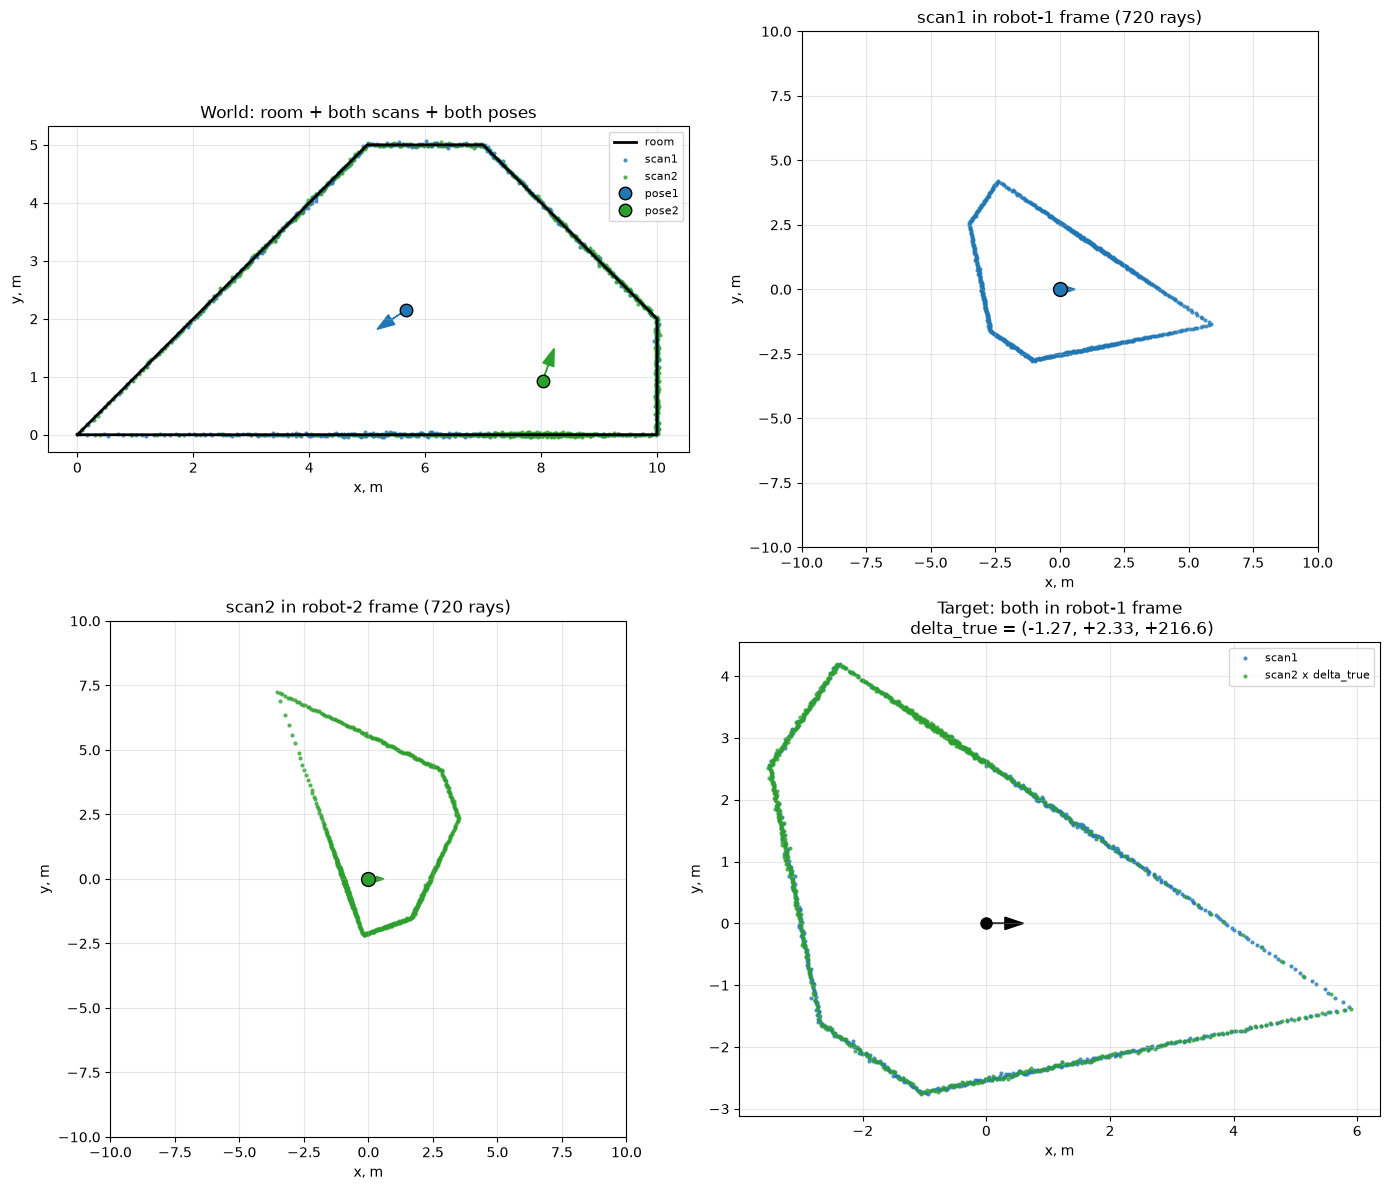

Time: 91 ms
Map: 180×228 cells, 5.0 cm/cell
Field: 1170×1218 cells, margin=24.7 m
True delta: (-1.270, +2.333, +216.56)
Est delta: (-1.250, +2.350, -143.66)
Pose error: 0.026 m = 0.23% of diagonal
Angle error: -0.22 deg


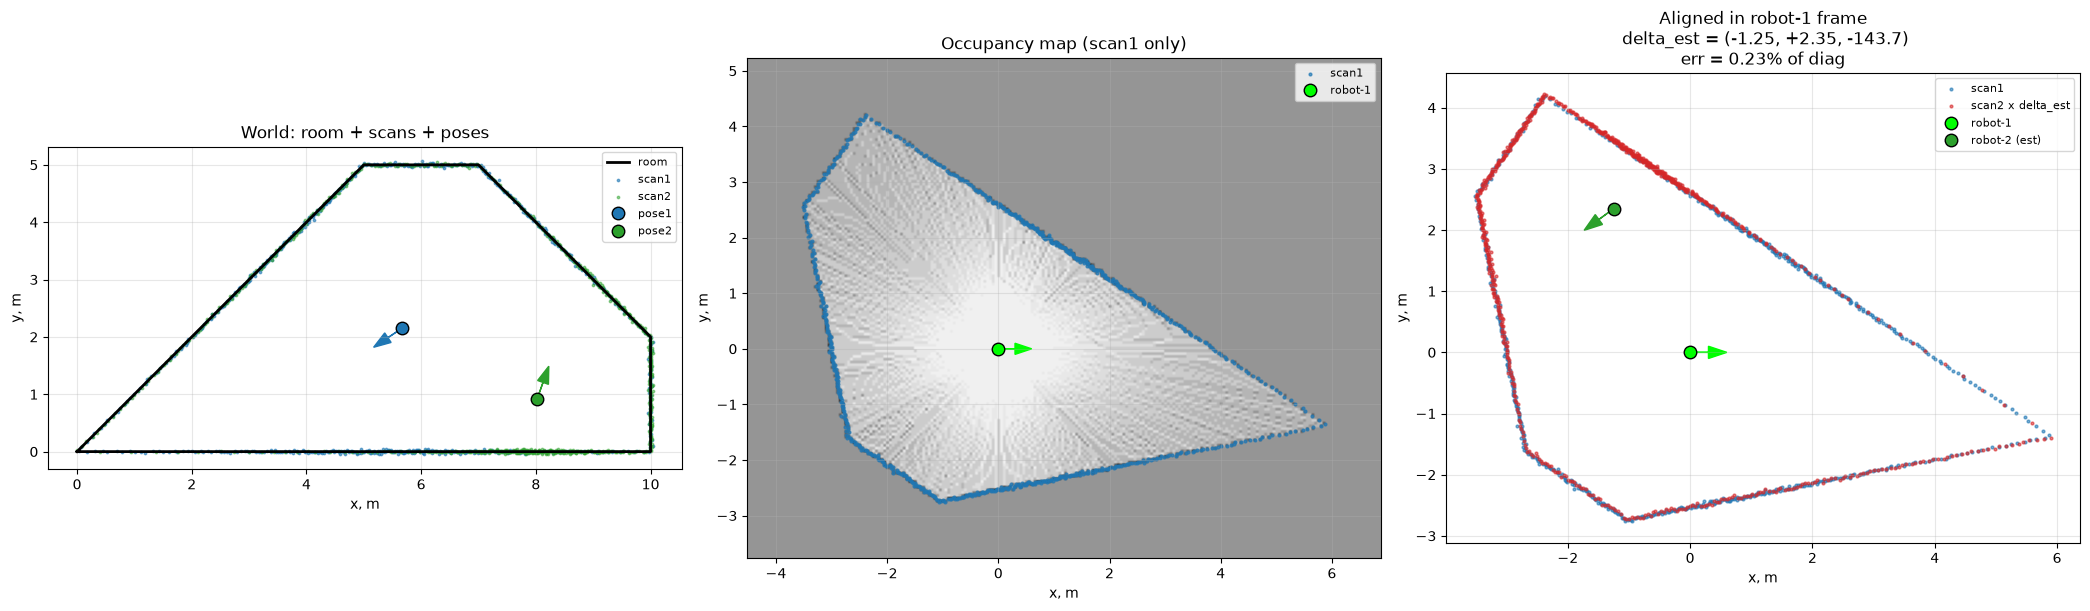

In [62]:
ROOM = Room(
    polygon=[
        Point(0.0, 0.0),
        Point(10.0, 0.0),
        Point(10.0, 2.0),
        Point(7.0, 5.0),
        Point(5.0, 5.0),
    ],
)
# Генерация поз и сканов
rng = np.random.default_rng(16)
gen = PoseGenerator(ROOM, rng=np.random.default_rng(16))
pose1 = gen.random()
pose2 = gen.random()

lidar = Lidar()
scan1 = lidar.scan(pose1, ROOM, rng=rng)
scan2 = lidar.scan(pose2, ROOM, rng=rng)
delta_true = pose1.inverse().compose(pose2)

print(f"Room:\t{len(ROOM.polygon)} vertices")
print(f"Lidar:\t{lidar.num_rays} rays,  max={lidar.max_range} m,  sigma={lidar.noise_std} m")
print(f"pose1:\t({pose1.position.x:+.3f}, {pose1.position.y:+.3f}, {math.degrees(pose1.theta):+.1f})")
print(f"pose2:\t({pose2.position.x:+.3f}, {pose2.position.y:+.3f}, {math.degrees(pose2.theta):+.1f})")
print(f"delta:\t({delta_true.position.x:+.3f}, {delta_true.position.y:+.3f}, {math.degrees(delta_true.theta):+.1f})")

# Визуализация поз и сканов
viz = ScanVisualizer(ROOM)
fig, axes = viz.plot_scan_setup(pose1, pose2, scan1, scan2, delta_true=delta_true)
plt.show()

# Построение карты занятости по scan1
mapper = Mapper()
occupancy_grid = mapper.build(scan1)

matcher = ScanMatcher(window_xy=8.0, window_theta=math.pi)
pts2 = polar_to_local(scan2)
margin = matcher.required_margin(
    max_scan_radius=float(np.linalg.norm(pts2, axis=1).max()),
    sigma=0.15,
    resolution=occupancy_grid.grid_spec.resolution,
)
likelihood_field = LikelihoodField(occupancy_grid, sigma=0.15, margin=margin)

t0 = time.perf_counter()
delta_est = matcher.match(likelihood_field, scan2)
elapsed = time.perf_counter() - t0

pose2_est = pose1.compose(delta_est)
pos_err = np.hypot(pose2_est.position.x - pose2.position.x, pose2_est.position.y - pose2.position.y)
ang_err = abs(pose2_est.theta - pose2.theta)
ang_err = min(ang_err, 2 * math.pi - ang_err)

xs = [point.x for point in ROOM.polygon]
ys = [point.y for point in ROOM.polygon]
diag = math.hypot(max(xs) - min(xs), max(ys) - min(ys))
rel_pos_err = 100 * pos_err / diag

print(f"Time: {elapsed*1000:.0f} ms")
print(f"Map: {occupancy_grid.grid_spec.height}×{occupancy_grid.grid_spec.width} cells, {occupancy_grid.grid_spec.resolution*100:.1f} cm/cell")
print(f"Field: {likelihood_field.grid_spec.height}×{likelihood_field.grid_spec.width} cells, margin={margin:.1f} m")
print(f"True delta: ({delta_true.position.x:+.3f}, {delta_true.position.y:+.3f}, {math.degrees(delta_true.theta):+.2f})")
print(f"Est delta: ({delta_est.position.x:+.3f}, {delta_est.position.y:+.3f}, {math.degrees(delta_est.theta):+.2f})")
print(f"Pose error: {pos_err:.3f} m = {rel_pos_err:.2f}% of diagonal")
print(f"Angle error: {math.degrees(ang_err):.2f} deg")

# Визуализация матчинга
fig, axes = viz.plot_match_result(
    pose1, pose2, scan1, scan2, occupancy_grid,
    delta_est, rel_pos_err=rel_pos_err,
)

### Тестирование на бенчмарке

In [63]:
def benchmark_matcher(room, n_runs=100, seed0=0, verbose=True):
    xs = [point.x for point in room.polygon]
    ys = [point.y for point in room.polygon]
    diag = math.hypot(max(xs) - min(xs), max(ys) - min(ys))

    results = []
    t_start = time.perf_counter()
    

    for i in range(n_runs):
        rng = np.random.default_rng(seed0 + i)
        gen = PoseGenerator(room, rng=rng)
        pose1, pose2 = gen.random(), gen.random()

        lidar = Lidar()
        scan1 = lidar.scan(pose1, room, rng=rng)
        scan2 = lidar.scan(pose2, room, rng=rng)
        delta_true = pose1.inverse().compose(pose2)

        mapper = Mapper()
        occupancy_grid = mapper.build(scan1)

        matcher = ScanMatcher()
        pts2 = polar_to_local(scan2)
        margin = matcher.required_margin(
            max_scan_radius=float(np.linalg.norm(pts2, axis=1).max()),
            sigma=0.15,
            resolution=occupancy_grid.grid_spec.resolution,
        )
        likelihood_field = LikelihoodField(occupancy_grid, sigma=0.15, margin=margin)

        t0 = time.perf_counter()
        delta_est = matcher.match(likelihood_field, scan2)
        dt = time.perf_counter() - t0

        pose2_est = pose1.compose(delta_est)
        pos_err = np.hypot(
            pose2_est.position.x - pose2.position.x,
            pose2_est.position.y - pose2.position.y
        )
        ang_err = abs(pose2_est.theta - pose2.theta)
        ang_err = min(ang_err, 2 * math.pi - ang_err)
        rel_pct = 100 * pos_err / diag

        results.append({
            "seed": seed0 + i,
            "time_s": dt,
            "pos_err_m": pos_err,
            "ang_err_deg": math.degrees(ang_err),
            "rel_err_pct": rel_pct,
            "delta_true": delta_true,
            "delta_est": delta_est,
        })

        if verbose and (i + 1) % 10 == 0:
            print(f"run {i+1:3d}/{n_runs} (last: pos_err={pos_err*100:.2f} cm, ang_err={math.degrees(ang_err):.2f}°)")

    total = time.perf_counter() - t_start

    errs = np.array([r["rel_err_pct"] for r in results])
    pes = np.array([r["pos_err_m"] for r in results])
    aes = np.array([r["ang_err_deg"] for r in results])
    times = np.array([r["time_s"] for r in results])

    print(f"Benchmark: {n_runs} runs  (total {total:.1f} sec) ===")
    print(f"rel_pos_err (% of diag):")
    print(f"\tmean = {errs.mean():.4f}  (pm {errs.std():.4f})")
    print(f"\tmedian = {np.median(errs):.4f}")
    print(f"\tmin = {errs.min():.4f}")
    print(f"\tmax = {errs.max():.4f}")
    print(f"pos_err (m):")
    print(f"\tmean = {pes.mean():.4f}")
    print(f"\tmax = {pes.max():.4f}")
    print(f"ang_err (deg):")
    print(f"\tmean = {aes.mean():.4f}")
    print(f"\tmax = {aes.max():.4f}")
    print(f"time (sec):")
    print(f"\tmean = {times.mean():.4f}")
    print(f"\tmax = {times.max():.4f}")
    print(f"pass rate:")
    for thr in [20.0, 10.0, 5.0, 0.3]:
        n_ok = int(np.sum(errs <= thr))
        print(f" <= {thr:4.1f}% : {n_ok:3d}/{n_runs} ({100 * n_ok / n_runs:.1f}%)")

    return results

In [64]:
def diagnose_failing_seeds(room, results, n_show=3, matcher=None):
    if matcher is None:
        matcher = ScanMatcher()
    viz = ScanVisualizer(room)

    room_pts  = np.array([[point.x, point.y] for point in room.polygon])
    room_diag = math.hypot(*np.ptp(room_pts, axis=0))

    bad = sorted(results, key=lambda r: -r["rel_err_pct"])[:n_show]
    diag = []

    for r in bad:
        seed = r["seed"]
        rng  = np.random.default_rng(seed)
        gen  = PoseGenerator(room, rng=rng)
        p1, p2 = gen.random(), gen.random()
        lidar = Lidar()
        s1 = lidar.scan(p1, room, rng=rng)
        s2 = lidar.scan(p2, room, rng=rng)
        dt = p1.inverse().compose(p2)

        mapper = Mapper()
        occupancy_grid = mapper.build(s1)

        pts2 = polar_to_local(s2)
        margin = matcher.required_margin(
            max_scan_radius=float(np.linalg.norm(pts2, axis=1).max()),
            sigma=0.15,
            resolution=occupancy_grid.grid_spec.resolution,
        )
        likelihood_field = LikelihoodField(occupancy_grid, sigma=0.15, margin=margin)
        de = matcher.match(likelihood_field, s2)

        st = likelihood_field.score(dt.apply(pts2))
        se = likelihood_field.score(de.apply(pts2))

        rel_err = 100.0 * math.hypot(
            de.position.x - dt.position.x,
            de.position.y - dt.position.y
        ) / room_diag

        verdict = "score ОК" if st > se else "score неоднозначен"
        print(f"seed = {seed}")
        print(f"pos_err = {r['pos_err_m']:.2f} m")
        print(f"ang_err = {r['ang_err_deg']:.1f} grad")
        print(f"delta_true: ({dt.position.x:+.2f}, {dt.position.y:+.2f}, {math.degrees(dt.theta):+.1f})")
        print(f"delta_est: ({de.position.x:+.2f}, {de.position.y:+.2f}, {math.degrees(de.theta):+.1f})")
        print(f"s_true = {st:.1f}")
        print(f"s_est = {se:.1f}")
        print(f"delta = {st - se:+.1f} - {verdict}")

        diag.append({
            "seed": seed, 
            "r": r,
            "dt": dt, 
            "de": de, 
            "st": st, 
            "se": se,
            "rel_err": rel_err,
        })

        fig, _ = viz.plot_match_result(
            pose1=p1, pose2=p2,
            scan1=s1, scan2=s2,
            occupancy_grid=occupancy_grid, delta_est=de,
            rel_pos_err=rel_err,
            show=False,
        )
        fig.suptitle(f"seed={seed} | pos_err={r['pos_err_m']:.2f} m, ang_err={r['ang_err_deg']:.1f} deg", fontsize=13)
        plt.tight_layout()
        plt.show()

    return diag

In [65]:
results = benchmark_matcher(ROOM, n_runs=100, seed0=0)

run  10/100 (last: pos_err=0.54 cm, ang_err=0.15°)
run  20/100 (last: pos_err=0.39 cm, ang_err=0.14°)
run  30/100 (last: pos_err=4.71 cm, ang_err=0.38°)
run  40/100 (last: pos_err=2.02 cm, ang_err=0.13°)
run  50/100 (last: pos_err=2.31 cm, ang_err=0.18°)
run  60/100 (last: pos_err=1.45 cm, ang_err=0.19°)
run  70/100 (last: pos_err=1.21 cm, ang_err=0.26°)
run  80/100 (last: pos_err=2.46 cm, ang_err=0.19°)
run  90/100 (last: pos_err=2.52 cm, ang_err=0.12°)
run 100/100 (last: pos_err=3.28 cm, ang_err=0.14°)
Benchmark: 100 runs  (total 20.0 sec) ===
rel_pos_err (% of diag):
	mean = 0.1858  (pm 0.0788)
	median = 0.1807
	min = 0.0351
	max = 0.4213
pos_err (m):
	mean = 0.0208
	max = 0.0471
ang_err (deg):
	mean = 0.1378
	max = 0.5845
time (sec):
	mean = 0.1580
	max = 2.1671
pass rate:
 <= 20.0% : 100/100 (100.0%)
 <= 10.0% : 100/100 (100.0%)
 <=  5.0% : 100/100 (100.0%)
 <=  0.3% :  91/100 (91.0%)


seed = 29
pos_err = 0.05 m
ang_err = 0.4 grad
delta_true: (-1.44, -1.08, +1.0)
delta_est: (-1.40, -1.05, +1.4)
s_true = 673.8
s_est = 668.7
delta = +5.2 - score ОК


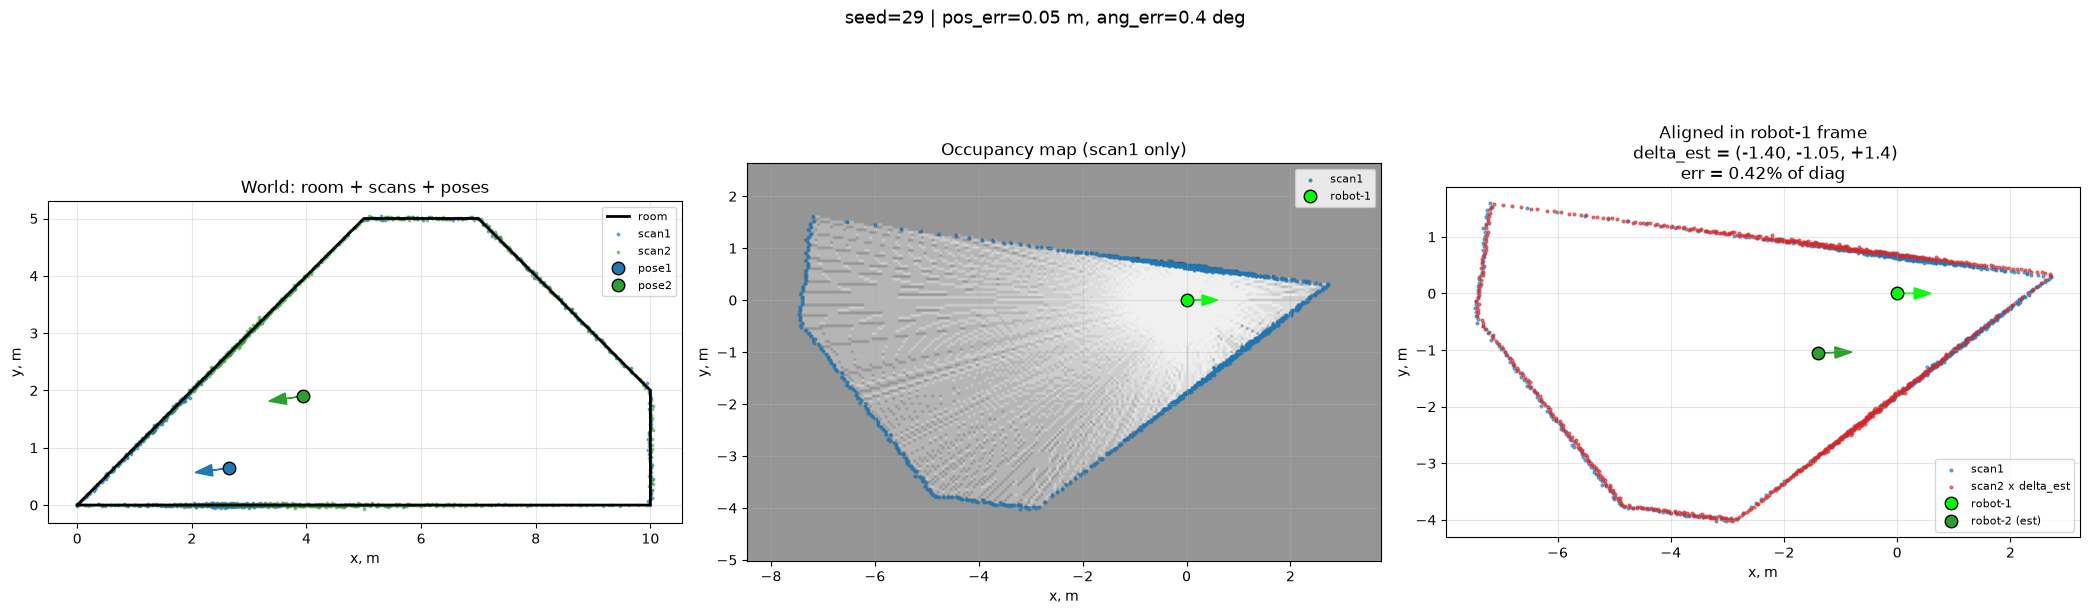

seed = 64
pos_err = 0.04 m
ang_err = 0.4 grad
delta_true: (+0.02, -1.32, -78.1)
delta_est: (+0.00, -1.35, -78.5)
s_true = 700.4
s_est = 697.1
delta = +3.2 - score ОК


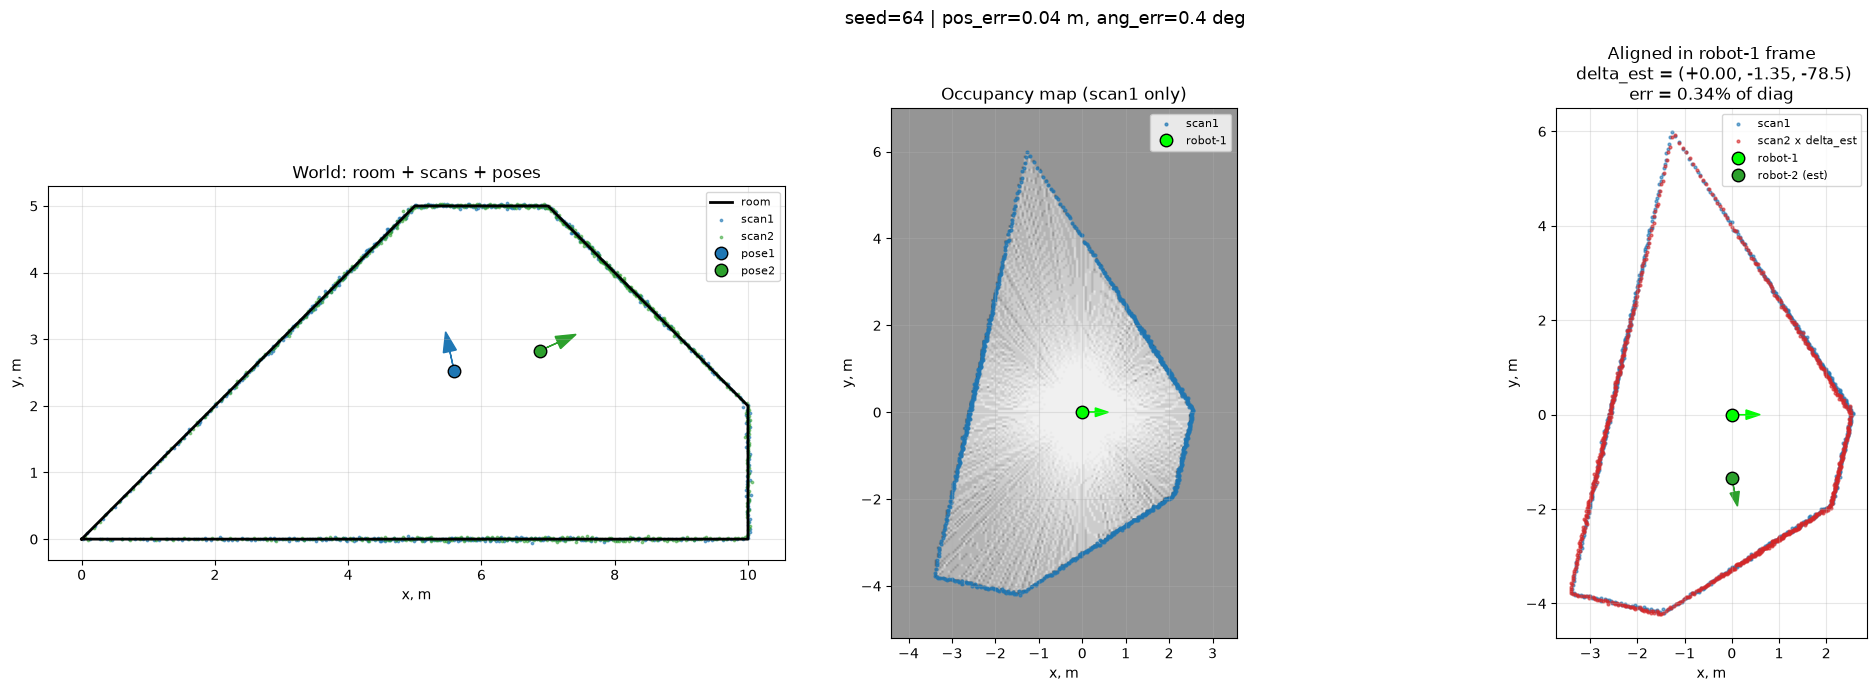

seed = 42
pos_err = 0.04 m
ang_err = 0.4 grad
delta_true: (+1.78, +2.73, +24.5)
delta_est: (+1.75, +2.70, +24.1)
s_true = 694.1
s_est = 690.4
delta = +3.7 - score ОК


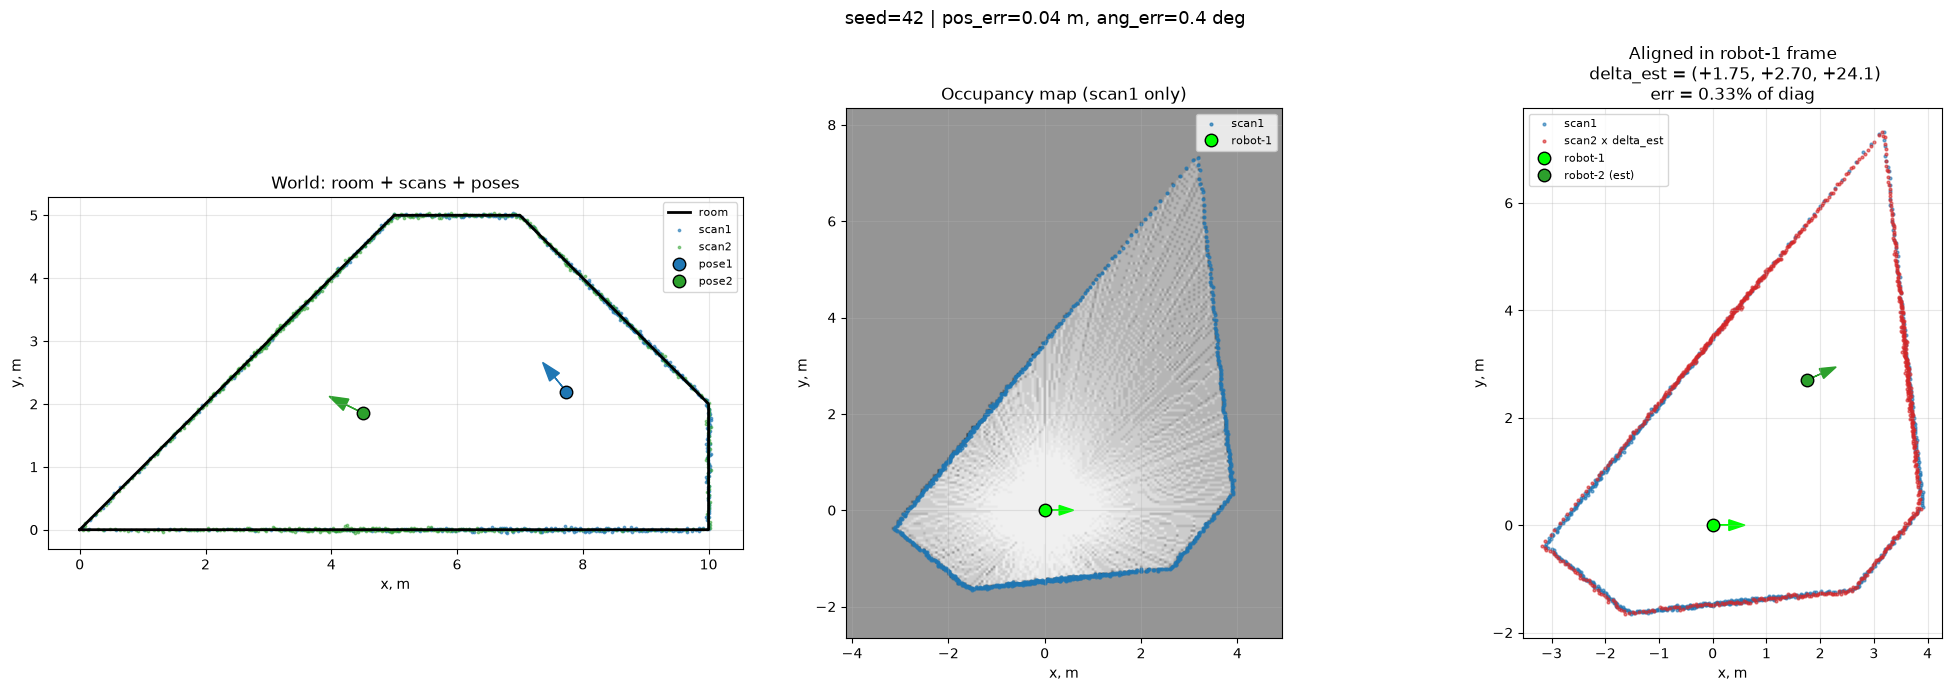

In [66]:
diag = diagnose_failing_seeds(ROOM, results, n_show=3, matcher=ScanMatcher())